# Mini-Project 1: UBOS District Population Forecaster

**Question.** A district planning unit wants 5-year population forecasts (2025-2029) to plan primary-school classrooms.

**Approach.** Model each district with a validated class, compare three forecasting models by training on 2015-2021 and testing on 2022-2024, pick the best model per district, refit on all ten years, forecast, and convert the forecast into classrooms. The extension adds bootstrap prediction intervals and a critique of the Fibonacci-ratio model.

**Reusable code** lives in `src/population_model.py` (`DistrictPopulation`, `Forecaster` and subclasses, error metrics, `bootstrap_prediction_intervals`, `classrooms_needed`). Tests are in `tests/test_project1.py`.

**Data.** Kampala, Wakiso and Gulu are the given illustrative figures. **Mbarara and Jinja are invented by me for illustration** and are not UBOS numbers; replace them with real UBOS estimates (cited) for extra credit.

**Units.** Population in thousands of people.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.population_model import (
    DistrictPopulation, ExponentialGrowth, FibonacciRatio, LinearTrend,
    bootstrap_prediction_intervals, classrooms_needed, evaluate_models, fibonacci, mae, mape, rmse,
)

SEED = 2026
YEARS = np.arange(2015, 2025)
LAST_TRAIN, HORIZON = 2021, 5
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.options.display.float_format = "{:,.2f}".format

## Task 1. `DistrictPopulation`

In [2]:
districts = [
    DistrictPopulation("Kampala", YEARS, [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800]),
    DistrictPopulation("Wakiso",  YEARS, [950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670]),
    DistrictPopulation("Gulu",    YEARS, [320, 330, 345, 360, 375, 390, 410, 430, 455, 480]),
    # Invented for illustration (not UBOS data):
    DistrictPopulation("Mbarara", YEARS, [222, 229, 236, 245, 254, 263, 273, 284, 295, 307]),
    DistrictPopulation("Jinja",   YEARS, [470, 476, 483, 491, 499, 508, 518, 529, 540, 552]),
]
by_name = {d.name: d for d in districts}
print(districts, "\nlen(Kampala) =", len(by_name["Kampala"]))

# The class rejects bad input:
for bad in [dict(years=[2015, 2016], population=[1.0]), dict(years=[2015, 2016], population=[1.0, -2.0])]:
    try:
        DistrictPopulation("bad", **bad)
    except ValueError as e:
        print("Rejected:", e)

[DistrictPopulation('Kampala', 2015-2024, last=1,800k), DistrictPopulation('Wakiso', 2015-2024, last=1,670k), DistrictPopulation('Gulu', 2015-2024, last=480k), DistrictPopulation('Mbarara', 2015-2024, last=307k), DistrictPopulation('Jinja', 2015-2024, last=552k)] 
len(Kampala) = 10
Rejected: years (2) and population (1) must have equal length
Rejected: population values must be finite and non-negative


## Task 2. Descriptive statistics: `statistics` vs NumPy

In [3]:
rows = {}
for d in districts:
    s, n0, n1 = d.describe_statistics(), d.describe_numpy(ddof=0), d.describe_numpy(ddof=1)
    rows[d.name] = {
        "mean": s["mean"], "median": s["median"],
        "variance: statistics.variance": s["variance"],
        "variance: np.var (default, ddof=0)": n0["variance"],
        "variance: np.var(ddof=1)": n1["variance"],
        "std: statistics.stdev": s["std"], "std: np.std (ddof=0)": n0["std"],
    }
stats_table = pd.DataFrame(rows).T
display(stats_table)
k = by_name["Kampala"]
print("n =", len(k), "| ratio statistics.variance / np.var =", round(k.describe_statistics()["variance"] / k.describe_numpy(0)["variance"], 4), "= n/(n-1) =", round(len(k) / (len(k) - 1), 4))

,mean,median,variance: statistics.variance,"variance: np.var (default, ddof=0)",variance: np.var(ddof=1),std: statistics.stdev,std: np.std (ddof=0)
Kampala,"1,477.00","1,460.00","42,601.11","38,341.00","42,601.11",206.40,195.81
Wakiso,"1,280.00","1,260.00","60,066.67","54,060.00","60,066.67",245.09,232.51
Gulu,389.50,382.50,"2,885.83","2,597.25","2,885.83",53.72,50.96
Mbarara,260.80,258.50,824.84,742.36,824.84,28.72,27.25
Jinja,506.60,503.50,771.60,694.44,771.60,27.78,26.35


n = 10 | ratio statistics.variance / np.var = 1.1111 = n/(n-1) = 1.1111


**Why they differ.** `statistics.variance` is the **sample** variance: it divides the sum of squared deviations by $n-1$. `np.var` by default is the **population** variance: it divides by $n$. The argument `ddof` ("delta degrees of freedom") sets the divisor to $n-\text{ddof}$, so `np.var(x, ddof=1)` equals `statistics.variance(x)` exactly (see the table), and the two defaults differ by the factor $n/(n-1)=10/9$. The $n-1$ version corrects the downward bias that arises when the mean is estimated from the same data. Which to use: if the 10 years are a sample from a longer process, use $n-1$; if they are the whole population you care about, $n$ is correct. The same applies to `statistics.stdev` vs `np.std`.

## Task 3. Growth rates and CAGR

Year-on-year growth (%):


,Kampala,Wakiso,Gulu,Mbarara,Jinja
year,,,,,
2016,4.17,5.26,3.12,3.15,1.28
2017,4.00,7.00,4.55,3.06,1.47
2018,3.85,7.48,4.35,3.81,1.66
2019,5.19,6.09,4.17,3.67,1.63
2020,5.63,6.56,4.00,3.54,1.80
2021,5.33,6.92,5.13,3.80,1.97
2022,4.43,6.47,4.88,4.03,2.12
2023,4.24,6.08,5.81,3.87,2.08
2024,4.65,6.37,5.49,4.07,2.22


,CAGR 2015-2024 (%)
Wakiso,6.47
Kampala,4.61
Gulu,4.61
Mbarara,3.67
Jinja,1.80


Fastest growing in relative terms: Wakiso


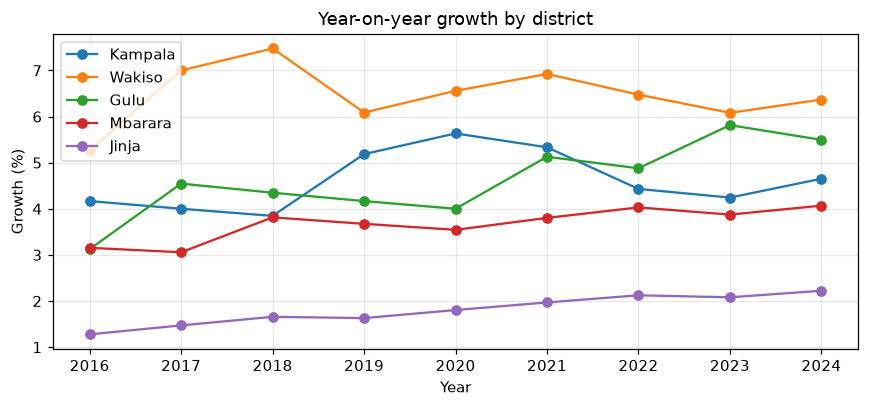

In [4]:
yoy = pd.DataFrame({d.name: d.yoy_growth() * 100 for d in districts}, index=YEARS[1:])
yoy.index.name = "year"
print("Year-on-year growth (%):")
display(yoy)
cagr = pd.Series({d.name: d.cagr() * 100 for d in districts}, name="CAGR 2015-2024 (%)")
display(cagr.sort_values(ascending=False).to_frame())
print("Fastest growing in relative terms:", cagr.idxmax())

fig, ax = plt.subplots(figsize=(8, 3.8))
for c in yoy.columns:
    ax.plot(yoy.index, yoy[c], marker="o", label=c)
ax.set(title="Year-on-year growth by district", xlabel="Year", ylabel="Growth (%)")
ax.legend(); plt.tight_layout(); plt.show()

CAGR $=(P_{2024}/P_{2015})^{1/9}-1$ uses only the first and last values, so it summarises the average pace but ignores the path. Wakiso is growing fastest in relative terms, at roughly 6-7% a year since 2017. Gulu, Mbarara and Jinja show steadily *rising* annual rates, and Kampala moves in a 4-5.6% band. Kampala and Gulu have the same CAGR, but Kampala adds far more people in absolute terms because it starts from a much larger base.

## Task 4. Forecasting models

`Forecaster` is an abstract base class with `fit(years, values)` and `predict(horizon)`. Three subclasses:

1. **`LinearTrend`**: straight line fitted with `np.polyfit`; adds a constant number of people per year.
2. **`ExponentialGrowth`**: last value × (1 + CAGR)^k; adds a constant *percentage* per year.
3. **`FibonacciRatio`**: last value × the cumulative product of Fibonacci ratios 3/2, 5/3, 8/5, 13/8, ... (the previous cohort's approach). It does not use the data's growth at all.

In [5]:
MODELS = {"Linear trend": LinearTrend, "Exponential (CAGR)": ExponentialGrowth, "Fibonacci ratio": FibonacciRatio}
k = by_name["Kampala"]
for name, cls in MODELS.items():
    print(f"{name:20s} Kampala 2025-2029:", np.round(cls().fit(k.years, k.population).predict(5)).astype(int))

Linear trend         Kampala 2025-2029: [1851 1919 1987 2054 2122]
Exponential (CAGR)   Kampala 2025-2029: [1883 1970 2060 2155 2255]
Fibonacci ratio      Kampala 2025-2029: [ 2700  4500  7200 11700 18900]


## Task 5. Validation: train 2015-2021, test 2022-2024

Each model is fitted on 2015-2021 only and judged on how well it predicts the 2022-2024 values it has not seen. Metrics: MAE and RMSE (thousands of people) and MAPE (%). **Selection rule: lowest RMSE** (it penalises large misses most); the other two metrics are shown so you can check that they agree.

In [6]:
validation, best_model = {}, {}
for d in districts:
    table = pd.DataFrame(evaluate_models(d, [cls() for cls in MODELS.values()], LAST_TRAIN)).set_index("model")
    validation[d.name] = table
    best_model[d.name] = table["RMSE"].idxmin()
    print(f"\n{d.name}  ->  best model: {best_model[d.name]}")
    display(table)


Kampala  ->  best model: Exponential (CAGR)


,MAE,RMSE,MAPE (%)
model,,,
Linear trend,37.62,38.97,2.17
Exponential (CAGR),9.62,10.39,0.55
Fibonacci ratio,"2,490.00","2,939.48",141.47



Wakiso  ->  best model: Exponential (CAGR)


,MAE,RMSE,MAPE (%)
model,,,
Linear trend,49.40,52.37,3.09
Exponential (CAGR),6.80,8.05,0.42
Fibonacci ratio,"2,133.33","2,525.02",131.72



Gulu  ->  best model: Exponential (CAGR)


,MAE,RMSE,MAPE (%)
model,,,
Linear trend,18.57,20.29,4.01
Exponential (CAGR),9.44,10.87,2.02
Fibonacci ratio,638.33,753.82,136.65



Mbarara  ->  best model: Exponential (CAGR)


,MAE,RMSE,MAPE (%)
model,,,
Linear trend,6.65,7.09,2.23
Exponential (CAGR),2.74,2.97,0.91
Fibonacci ratio,432.67,510.60,143.75



Jinja  ->  best model: Exponential (CAGR)


,MAE,RMSE,MAPE (%)
model,,,
Linear trend,8.19,8.68,1.51
Exponential (CAGR),5.22,5.71,0.96
Fibonacci ratio,841.00,990.27,154.02


Exponential growth is selected for every district. The series are convex: the absolute increase per year keeps growing, so a straight line under-predicts the test years while constant compound growth tracks them. The Fibonacci-ratio model is off by more than 100% (MAPE) because it assumes about 60% growth per year, which nothing in the data supports. With only three test points the ranking between linear and exponential is less certain than the table suggests.

## Task 6. Forecast 2025-2029

The selected model is **refitted on all ten years** and used to forecast 2025-2029. Bootstrap 95% prediction intervals (extension) are computed here too and used in the plot.

In [7]:
N_BOOT = 2000
FC_YEARS = np.arange(2025, 2030)
forecasts, intervals = {}, {}
for d in districts:
    model = MODELS[best_model[d.name]]().fit(d.years, d.population)
    forecasts[d.name] = model.predict(HORIZON)
    intervals[d.name] = bootstrap_prediction_intervals(MODELS[best_model[d.name]](), d.years, d.population,
                                                       HORIZON, n_boot=N_BOOT, seed=SEED)

fc_table = pd.DataFrame(forecasts, index=FC_YEARS).T
fc_table.columns.name = "year (thousands)"
display(fc_table)

print("2029 forecast with 95% bootstrap prediction interval (thousands):")
display(pd.DataFrame({d: {"forecast": forecasts[d][-1], "lower 2.5%": intervals[d][0][-1], "upper 97.5%": intervals[d][1][-1]}
                      for d in forecasts}).T)

# Variance of actual vs forecast series
rows = {}
for d in districts:
    a, f = d.population, forecasts[d.name]
    resid = a - MODELS[best_model[d.name]]().fit(d.years, a).fitted()
    rows[d.name] = {
        "variance actual (10 yrs)": np.var(a, ddof=1),
        "variance forecast (5 yrs)": np.var(f, ddof=1),
        "ratio forecast/actual": np.var(f, ddof=1) / np.var(a, ddof=1),
        "mean annual change, actual": np.diff(a).mean(),
        "mean annual change, forecast": np.diff(f).mean(),
        "residual variance of actual": np.var(resid, ddof=1),
    }
display(pd.DataFrame(rows).T)

year (thousands),2025,2026,2027,2028,2029
Kampala,"1,882.95","1,969.72","2,060.49","2,155.44","2,254.76"
Wakiso,"1,778.03","1,893.04","2,015.49","2,145.86","2,284.67"
Gulu,502.12,525.26,549.46,574.78,601.27
Mbarara,318.26,329.93,342.03,354.58,367.58
Jinja,561.95,572.08,582.40,592.90,603.59


2029 forecast with 95% bootstrap prediction interval (thousands):


,forecast,lower 2.5%,upper 97.5%
Kampala,"2,254.76","2,197.77","2,287.40"
Wakiso,"2,284.67","2,253.47","2,309.84"
Gulu,601.27,575.02,607.96
Mbarara,367.58,360.27,369.12
Jinja,603.59,589.36,606.19


,variance actual (10 yrs),variance forecast (5 yrs),ratio forecast/actual,"mean annual change, actual","mean annual change, forecast",residual variance of actual
Kampala,"42,601.11","21,607.68",0.51,66.67,92.95,98.75
Wakiso,"60,066.67","40,131.36",0.67,80.00,126.66,30.90
Gulu,"2,885.83","1,536.55",0.53,17.78,24.79,13.82
Mbarara,824.84,380.16,0.46,9.44,12.33,1.11
Jinja,771.60,270.87,0.35,9.11,10.41,4.84


**What the variance comparison tells us.** The forecast series has a *smaller* variance than the actual series for every district, even though its year-on-year increases are *larger* (compare the mean annual changes). The difference is mostly an artefact of span: variance of a trending series grows roughly with the square of the time span covered, and the forecast covers 5 years against 10. So "lower variance" does not mean the forecast is calmer or safer. Two further points: (1) the forecast is a smooth deterministic curve with no year-to-year noise, whereas the actual series includes irregular movements (its residual variance is small but non-zero), so the forecast **understates real variability**; (2) variance here is dominated by the trend, not by volatility, so it is the wrong tool for judging forecast risk. Prediction intervals, not variance, express forecast uncertainty.

## Task 7. Actual, fitted and forecast values

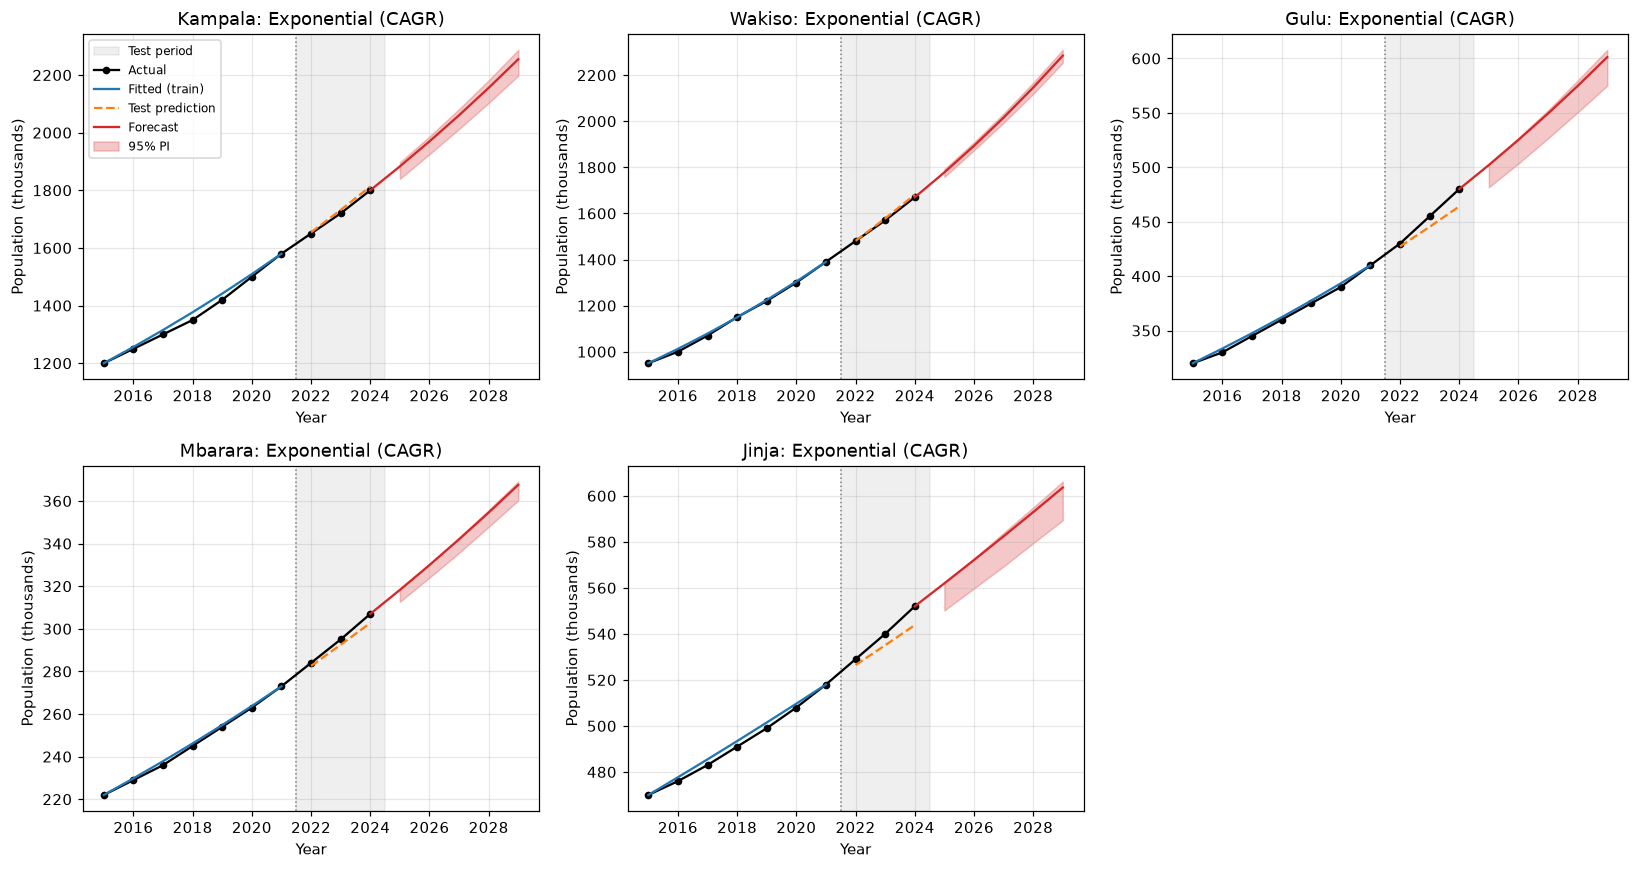

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for ax, d in zip(axes, districts):
    train, test = d.split(LAST_TRAIN)
    name = best_model[d.name]
    m_train = MODELS[name]().fit(train.years, train.population)
    m_full = MODELS[name]().fit(d.years, d.population)
    lo, hi, _ = intervals[d.name]

    ax.axvspan(LAST_TRAIN + 0.5, 2024.5, color="grey", alpha=0.12, label="Test period")
    ax.axvline(LAST_TRAIN + 0.5, color="grey", ls=":", lw=1)
    ax.plot(d.years, d.population, "ko-", ms=4, label="Actual")
    ax.plot(train.years, m_train.fitted(), "-", color="C0", label="Fitted (train)")
    ax.plot(test.years, m_train.predict(len(test)), "--", color="C1", label="Test prediction")
    ax.plot(np.r_[2024, FC_YEARS], np.r_[d.population[-1], forecasts[d.name]], "-", color="C3", label="Forecast")
    ax.fill_between(FC_YEARS, lo, hi, color="C3", alpha=0.25, label="95% PI")
    ax.set(title=f"{d.name}: {name}", xlabel="Year", ylabel="Population (thousands)")
for ax in axes[len(districts):]:
    ax.axis("off")
axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

## Task 8. Planning output: primary-school classrooms

Assumptions: 18% of the population is of primary-school age; a classroom holds 53 pupils; **existing classrooms just meet the 2024 need** (no stock data was given), so additional classrooms = need in 2029 minus need in 2024. Rounded up.

In [9]:
rows = {}
for d in districts:
    need24 = classrooms_needed(d.population[-1])
    need29 = classrooms_needed(forecasts[d.name][-1])
    rows[d.name] = {"pop 2024 (k)": d.population[-1], "pop 2029 forecast (k)": forecasts[d.name][-1],
                    "classrooms needed 2024": need24, "classrooms needed 2029": need29,
                    "additional by 2029": need29 - need24}
rooms = pd.DataFrame(rows).T
rooms = rooms.astype({c: int for c in ["classrooms needed 2024", "classrooms needed 2029", "additional by 2029"]})
display(rooms)
print("Total additional classrooms across the five districts:", int(rooms["additional by 2029"].sum()))

,pop 2024 (k),pop 2029 forecast (k),classrooms needed 2024,classrooms needed 2029,additional by 2029
Kampala,"1,800.00","2,254.76",6114,7658,1544
Wakiso,"1,670.00","2,284.67",5672,7760,2088
Gulu,480.00,601.27,1631,2043,412
Mbarara,307.00,367.58,1043,1249,206
Jinja,552.00,603.59,1875,2050,175


Total additional classrooms across the five districts: 4425


## Extension. Critique of the Fibonacci-ratio model

The bootstrap intervals above are the first part of the extension (1,000+ resamples; here 2,000). The shading is narrow because the in-sample residuals of the exponential fit are small, so the intervals capture irregular year-to-year noise but **not** model or parameter uncertainty; treat them as optimistic.

**Fibonacci-ratio critique.** The model multiplies the last value by 3/2, then 5/3, 8/5, 13/8 ... which converge to the golden ratio 1.618.

In [10]:
fr = FibonacciRatio()
print("Factors for the next 5 years:", np.round(fr.ratios(5), 3), "-> about +60% per year")
print("Observed CAGR range 2015-2024:", f"{cagr.min():.1f}% to {cagr.max():.1f}%")
k = by_name["Kampala"]
print(f"Kampala 2024 = {k.population[-1]:,.0f}k; Fibonacci-ratio 2029 = {fr.fit(k.years, k.population).predict(5)[-1]:,.0f}k "
      f"vs exponential 2029 = {forecasts['Kampala'][-1]:,.0f}k")
print("Fibonacci ratios settle at the golden ratio:", [round(b / a, 4) for a, b in zip(fibonacci(12)[8:], fibonacci(12)[9:])])

Factors for the next 5 years: [1.5   1.667 1.6   1.625 1.615] -> about +60% per year
Observed CAGR range 2015-2024: 1.8% to 6.5%
Kampala 2024 = 1,800k; Fibonacci-ratio 2029 = 18,900k vs exponential 2029 = 2,255k
Fibonacci ratios settle at the golden ratio: [1.6176, 1.6182, 1.618]


**When, if ever, is it defensible?** Only if the true growth factor is about 1.6 per period (about +62% a year) and approximately constant. That fits idealised, unconstrained, generation-based processes (the textbook rabbit problem, or an early epidemic or viral spread measured per generation), not district populations, which change through births, deaths and migration at a few percent a year. The model also has no parameter learned from the data: its factors are fixed numbers, so it ignores each district's actual growth, it can never slow down, and its forecast for Kampala is about 19 million people by 2029. It fails the validation test, and it fails basic plausibility.

## Findings & Limitations

**Model choice.** Exponential (CAGR) growth had the lowest RMSE in every district, 3 to 11 thousand people against 7 to 52 for the linear trend. The series are convex: the yearly increase in people keeps growing, so a straight line falls behind. The Fibonacci-ratio model failed badly (MAPE above 130%) because it assumes about 60% growth a year.

**Forecasts.** By 2029 the selected models give Kampala 2.25 million, Wakiso 2.28 million, Gulu 601 thousand, Mbarara 368 thousand and Jinja 604 thousand. Wakiso overtakes Kampala in 2029, but only if its roughly 6.5% compound growth continues unchanged. The classroom estimate is 2,088 additional classrooms for Wakiso, 1,544 for Kampala, 412 for Gulu, 206 for Mbarara and 175 for Jinja, 4,425 in total.

**Uncertainty.** The forecast series has lower variance than the actual series, but that is mainly because it covers 5 years rather than 10, not because it is calmer, and a smooth curve hides year-to-year noise. The bootstrap intervals are narrow (Kampala 2029: about 2,198 to 2,287 thousand) because they reflect only irregular noise around the fit, not the chance that growth slows.

**Limitations.** Ten data points and three test points make the ranking fragile, and CAGR depends heavily on the first and last values. Mbarara and Jinja are invented data. The models ignore births, deaths, migration and policy. The classroom estimate assumes an 18% school-age share, 53 pupils per classroom and that 2024 classrooms exactly meet 2024 demand, which real districts rarely do.